# Deber: Interpolación y polinomios de Taylor
## Sebastian Oña

### 2. ¿Cuántos términos necesita una calculadora?

0.006925270707505052


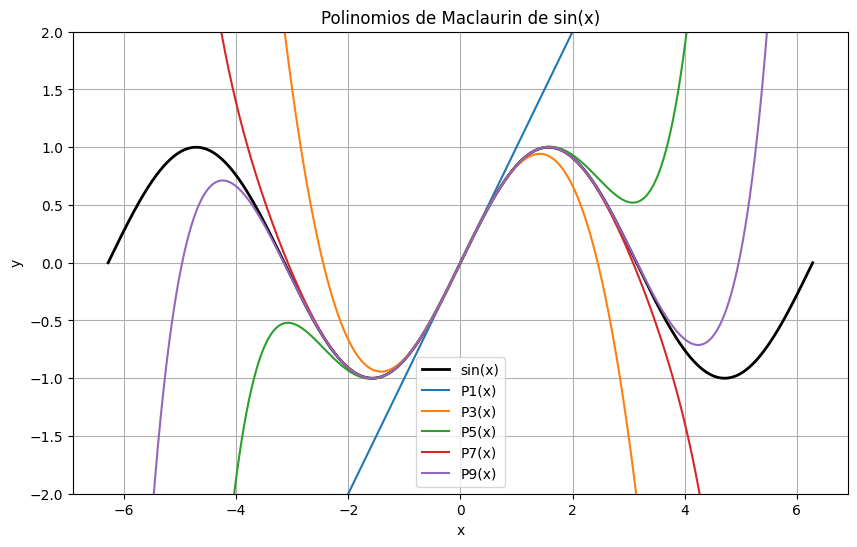

Grado  1: Error [-pi, pi] = 3.1415926536e+00 | Error [-pi/4, pi/4] = 7.8291382211e-02
Grado  3: Error [-pi, pi] = 2.0261201265e+00 | Error [-pi/4, pi/4] = 2.4541299774e-03
Grado  5: Error [-pi, pi] = 5.2404391342e-01 | Error [-pi/4, pi/4] = 3.6264592813e-05
Grado  7: Error [-pi, pi] = 7.5220615904e-02 | Error [-pi/4, pi/4] = 3.1161136949e-07
Grado  9: Error [-pi, pi] = 6.9252707075e-03 | Error [-pi/4, pi/4] = 1.7503195560e-09
Grado 11: Error [-pi, pi] = 4.4516023821e-04 | Error [-pi/4, pi/4] = 6.9281247406e-12
Grado 13: Error [-pi, pi] = 2.1142567558e-05 | Error [-pi/4, pi/4] = 2.0317081351e-14
Grado 15: Error [-pi, pi] = 7.7278588964e-07 | Error [-pi/4, pi/4] = 3.3306690739e-16
Grado 17: Error [-pi, pi] = 2.2419510510e-08 | Error [-pi/4, pi/4] = 3.3306690739e-16
Grado 19: Error [-pi, pi] = 5.2891848772e-10 | Error [-pi/4, pi/4] = 3.3306690739e-16
Grado 21: Error [-pi, pi] = 1.0347978539e-11 | Error [-pi/4, pi/4] = 3.3306690739e-16


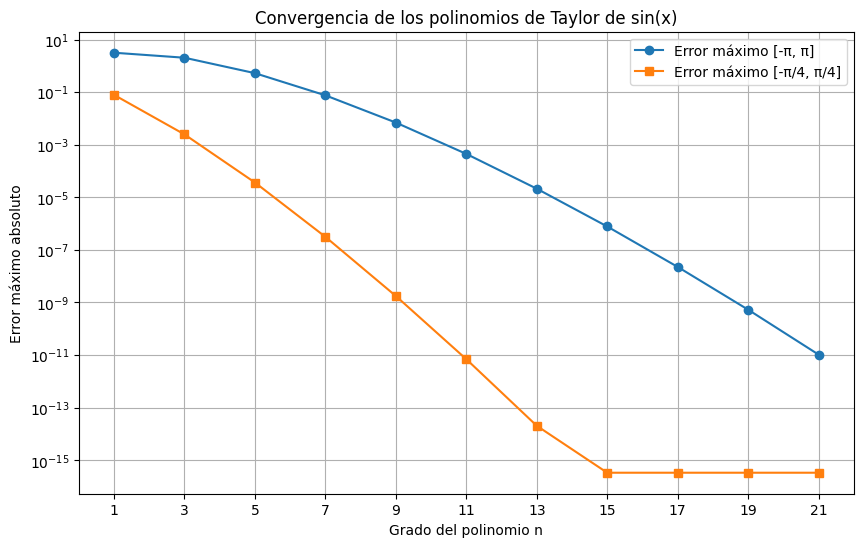

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# funcion de taylor

def taylor_sin(x, n):
    """Polinomio de Maclaurin de sin(x) de grado n impar."""
    if n < 1 or n % 2 == 0:
        raise ValueError("El grado n debe ser impar y mayor o igual a 1")

    x = np.asarray(x, dtype=float)
    termino = x.copy()
    suma = termino.copy()

    for k in range((n - 1) // 2):
        termino = termino * (-x**2) / ((2*k + 2)*(2*k + 3))
        suma += termino

    return suma

print(taylor_sin(np.pi, 9))  

# 2. GRÁFICA 1: sin(x) Y POLINOMIOS DE TAYLOR

x = np.linspace(-2*np.pi, 2*np.pi, 2001)

plt.figure(figsize=(10, 6))

plt.plot(x, np.sin(x), label="sin(x)", color="black", linewidth=2)

for n in [1, 3, 5, 7, 9]:
    plt.plot(x, taylor_sin(x, n), label=f"P{n}(x)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Polinomios de Maclaurin de sin(x)")
plt.ylim(-2, 2)
plt.legend()
plt.grid(True)
plt.show()


# 3. CALCULAR ERRORES MÁXIMOS

grados = np.arange(1, 22, 2)

a = np.linspace(-np.pi, np.pi, 2001)
b = np.linspace(-np.pi/4, np.pi/4, 2001)

errores_a = []
errores_b = []

for n in grados:

    error_a = np.max(np.abs(np.sin(a) - taylor_sin(a, n)))
    error_b = np.max(np.abs(np.sin(b) - taylor_sin(b, n)))

    errores_a.append(error_a)
    errores_b.append(error_b)

    print(f"Grado {n:2d}: Error [-pi, pi] = {error_a:.10e} | "
          f"Error [-pi/4, pi/4] = {error_b:.10e}")


# 4. GRÁFICA 2: ERRORES MÁXIMOS EN ESCALA LOGARÍTMICA

plt.figure(figsize=(10, 6))

plt.semilogy(grados, errores_a, "o-", label="Error máximo [-π, π]")
plt.semilogy(grados, errores_b, "s-", label="Error máximo [-π/4, π/4]")

plt.xlabel("Grado del polinomio n")
plt.ylabel("Error máximo absoluto")
plt.title("Convergencia de los polinomios de Taylor de sin(x)")

plt.xticks(grados)
plt.legend()
plt.grid(True, which="both")
plt.show()

### 3. Una función suave cuya serie no converge

S40(0.9) = 0.552583958
S40(1.1) = 1121.974778121


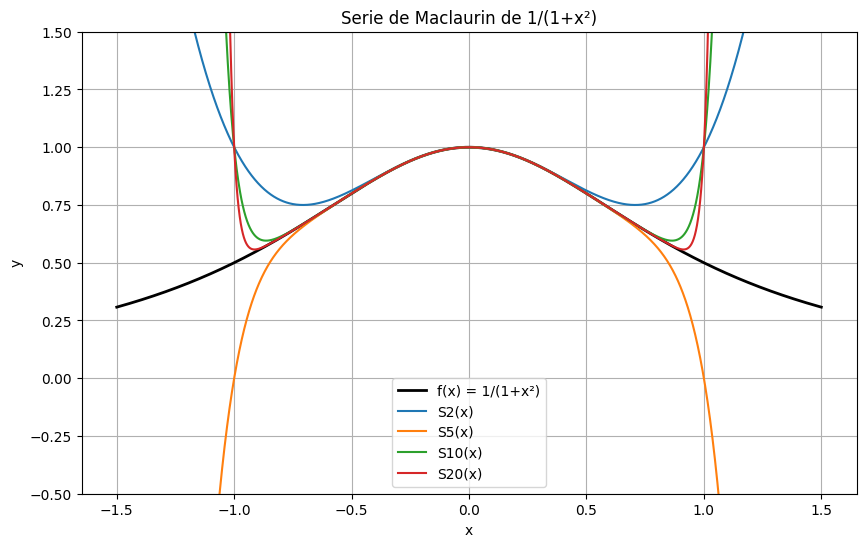

S40(0.9) = 0.552583958
S40(1.1) = 1121.974778121


In [6]:
import numpy as np
import matplotlib.pyplot as plt

def serie_geometrica(x, N):
    """Serie de Maclaurin de 1/(1+x²), grado 2N."""
    x = np.asarray(x, dtype=float)
    termino = np.ones_like(x)
    suma = termino.copy()

    for k in range(1, N + 1):
        termino = termino * (-x**2)
        suma = suma + termino

    return suma

S_40 = serie_geometrica(0.9, 40)
S_40_1_1 = serie_geometrica(1.1, 40)

print(f"S40(0.9) = {S_40:.9f}")
print(f"S40(1.1) = {S_40_1_1:.9f}")

# GRÁFICA 3
x = np.linspace(-1.5, 1.5, 2001)

plt.figure(figsize=(10, 6))

plt.plot(x, 1/(1+x**2), label="f(x) = 1/(1+x²)",
         color="black", linewidth=2)

for N in [2, 5, 10, 20]:
    plt.plot(x, serie_geometrica(x, N), label=f"S{N}(x)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Serie de Maclaurin de 1/(1+x²)")
plt.ylim(-0.5, 1.5)
plt.legend()
plt.grid(True)
plt.show()


# VERIFICAR LOS VALORES
print(f"S40(0.9) = {serie_geometrica(0.9, 40):.9f}")
print(f"S40(1.1) = {serie_geometrica(1.1, 40):.9f}")  